# Financial Data Quality, Fixed Income Yield Curves, and Equity Risk Analysis

This notebook investigates three interconnected areas of quantitative finance:

1. **Data Quality Assessment** — Distinguishing structured from unstructured financial data and identifying common data quality problems that affect downstream analysis.
2. **Government Bond Yield-Curve Modeling** — Fitting Nelson-Siegel and cubic spline models to Nigerian FGN bond data, and applying Principal Component Analysis (PCA) to decompose US Treasury yield-curve movements.
3. **Technology ETF Risk Decomposition** — Analysing the Vanguard Information Technology ETF ($VGT) to compute daily returns, the covariance structure, and principal components of constituent-stock risk.

> **Data sources:** Nigerian FGN bond data (Excel), FRED API (US Treasury yields), AlphaVantage API ($VGT constituents).

---

# Part 1 — Financial Data Quality Assessment

## Structured Data: Identifying Quality Problems

The table below reproduces a deliberately corrupted equity price feed — a common occurrence when ingesting raw data from multiple vendors. The highlighted issues (missing values, outliers, mis-formatted dates, and impossible prices) represent failure modes that must be detected before any downstream modelling.

In [ ]:
import pandas as pd

# Create the table
data = {
    "Date": ["2025-01-05", "2025-01-06", "2025-01-07", "2025-13-08", "2025-01-09"],
    "Ticker": ["APPL", "AAPL", "AAPL", "APLE", "AAPL"],
    "Open": [250.5, "-", 260, 265, 270],
    "Close": [255.2, 260, 99999, 270, "" ],
    "Volume": [1000000, "N/A", 800000, "???", 850000]
}

df = pd.DataFrame(data)

# Display the DataFrame
df


,Date,Ticker,Open,Close,Volume
0,2025-01-05,APPL,250.5,255.2,1000000
1,2025-01-06,AAPL,-,260,N/A
2,2025-01-07,AAPL,260,99999,800000
3,2025-13-08,APLE,265,270,???
4,2025-01-09,AAPL,270,,850000


## B.	Why this is a poor-quality structured data?

This stock market data is structured because it can be organized into rows and columns, with defined fields. But it shows poor quality because:

1.	The ticker names don’t match — “APPL” and “APLE” are simple typos of Apple’s real code, “AAPL,” which makes the data inconsistent.

2.	Some key details are missing, like a blank Close price or a dashed Open price, showing poor completeness.

3.	One row has an unrealistic Close price of 99999 and a date written as “2025-13-08,” which is not even valid.

4.	The Volume column contains entries like “N/A,” and “???,” instead of real numbers, this makes the data hard to trust or use for analysis.

## C.	Example of Poor-Quality Unstructured Data

OMG 😭😭 stock mkt craasshhh!!! $$$$ buyyyy nowwwwwww 99.999999% profits. visit my link: https://abc123.com/🔥🔥🔥 LOLZZZ #stonks #??? @@@

## D.	Why this is a poor-quality unstructured data

This tweet is unstructured because it’s just free text mixed with emojis, symbols, hashtags, and a spammy link — not organized in rows and columns. It shows poor quality because:

1.	It has excessive spelling errors and stretched words (“craasshhh,” “buyyyy”).

2.	It mixes random symbols, emojis, and hashtags that add noise instead of meaning.

3.	The exaggerated number “99.999999% profits” is unrealistic and misleading.

4.	A suspicious link is included, which lowers trustworthiness of data.

# Government Bond Yield-Curve Modeling

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from scipy.optimize import minimize
from scipy.interpolate import UnivariateSpline


Nigerian FGN Bonds was selected as the government security data to be used for the analysis downloaded from CBN data bank.

Maturities ranges from short terms of 40 days to 30 years; the data was clean and the tenor years were all converted to years so as to conduct a good graph

In [ ]:
# Load the Excel file
df = pd.read_excel("data/FGN_Bonds_in_Excel.xlsx")

# Check the first few rows
df.head()


,auctionDate,securityType,tenor,maturityDate,totalSubscription,totalSuccessful,rangeBid,successfulBidRates,rate,trueYield,amtOffered,netValue
0,19/06/2023,FGN BOND,10YEAR,26/06/2029,154000.340,86000.382,12.4900-17.0000,12.4900-13.9000,13.90,0.0,90000.0,86000.382
1,19/06/2023,FGN BOND,10YEAR,21/06/2033,34000.453,18000.570,12.5000-16.2500,12.5000-14.7000,14.70,0.0,90000.0,18000.570
2,19/06/2023,FGN BOND,15YEAR,21/06/2038,152000.612,100000.643,13.0000-16.7500,13.0000-15.4500,15.45,0.0,90000.0,100000.643
3,19/06/2023,FGN BOND,30YEAR,21/06/2053,2930.712,2210.562,14.6000-16.8000,14.6000-15.7000,15.70,0.0,90000.0,2210.562
4,17/05/2023,FGN BOND,10YEAR,27/04/2032,5000.109,2000.059,13.9300 - 15.5000,13.9300-14.8000,14.80,0.0,90000.0,94000.500


In [ ]:
def clean_tenor(tenor):
    """Convert messy Tenor to decimal years."""
    if pd.isna(tenor):
        return np.nan
    # Remove text
    numeric_str = re.sub(r'[^\d]', '', str(tenor))
    if numeric_str == '':
        return np.nan
    number = int(numeric_str)
    # >30 → days, ≤30 → years
    if number > 30:
        return number / 365
    else:
        return float(number)

# Apply cleaning
df['Maturity_Years'] = df['tenor'].apply(clean_tenor)

# Quick check
df[['tenor', 'Maturity_Years']].head(10)


,tenor,Maturity_Years
0,10YEAR,10.0
1,10YEAR,10.0
2,15YEAR,15.0
3,30YEAR,30.0
4,10YEAR,10.0
5,20YEAR,20.0
6,30YEAR,30.0
7,10YEAR,10.0
8,20YEAR,20.0
9,30YEAR,30.0


In [ ]:
# we used 'trueyield' (values like 6.5407 -> meaning 6.5407%)
df['trueYield'] = pd.to_numeric(df['trueYield'], errors='coerce')
# we then treat non-positive or placeholder zeros as missing for fitting:
df.loc[df['trueYield'] <= 0, 'trueYield'] = np.nan
df['yield_dec'] = df['trueYield'] / 100.0   # now in decimal (0.0654 = 6.54%)


In [ ]:
# We drop rows with missing values
df_clean = df.dropna(subset=['Maturity_Years', 'yield_dec'])

A Nelson Siegel model was conducted on it, we found our model's parameter to be:

Fitted parameters

beta0 = 0.08489073

beta1 = 0.00619694

beta2 = 0.14364572

tau   = 4.24501023

In [ ]:
# Nelson-Siegel function
def nelson_siegel(params, maturities):
    beta0, beta1, beta2, tau = params
    t = maturities
    term = (1 - np.exp(-t/tau)) / (t/tau)
    return beta0 + beta1*term + beta2*(term - np.exp(-t/tau))

# Objective function to minimize squared error
def objective(params, maturities, yields):
    fitted = nelson_siegel(params, maturities)
    return np.sum((yields - fitted)**2)

# Initial guess
init_params = [0.05, -0.02, 0.02, 1.0]  # beta0, beta1, beta2, tau

maturities = df_clean['Maturity_Years'].values
yields = df_clean['yield_dec'].values

res = minimize(objective, init_params, args=(maturities, yields), method='L-BFGS-B')

print("Fitted parameters (beta0, beta1, beta2, tau):", res.x)


Fitted parameters (beta0, beta1, beta2, tau): [0.08489142 0.00619627 0.14364413 4.24495324]


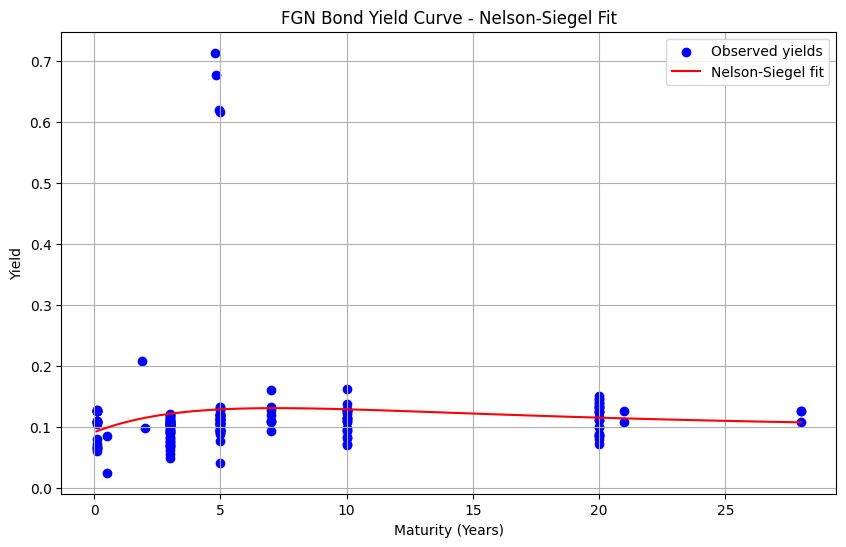

In [ ]:
# Generate smooth curve
t_fit = np.linspace(min(maturities), max(maturities), 100)
y_fit = nelson_siegel(res.x, t_fit)

plt.figure(figsize=(10,6))
plt.scatter(maturities, yields, label='Observed yields', color='blue')
plt.plot(t_fit, y_fit, label='Nelson-Siegel fit', color='red')
plt.xlabel('Maturity (Years)')
plt.ylabel('Yield')
plt.title('FGN Bond Yield Curve - Nelson-Siegel Fit')
plt.legend()
plt.grid(True)
plt.show()

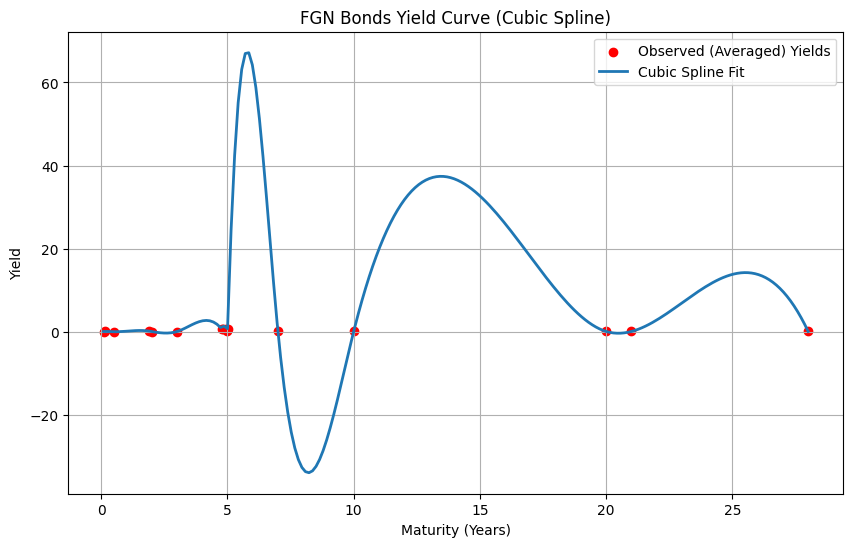

In [ ]:
# Drop missing
df_fit = df.dropna(subset=["Maturity_Years","yield_dec"])

# Average yields for duplicate maturities
df_avg = df_fit.groupby("Maturity_Years", as_index=False)["yield_dec"].mean()

# Extract clean x, y
maturities = df_avg["Maturity_Years"].values
yields = df_avg["yield_dec"].values

# Fit cubic spline (now safe)
spline = UnivariateSpline(maturities, yields, k=3, s=0)

# Predict on smooth grid
maturity_grid = np.linspace(min(maturities), max(maturities), 200)
yield_spline = spline(maturity_grid)

# Plot
plt.figure(figsize=(10,6))
plt.scatter(maturities, yields, color="red", label="Observed (Averaged) Yields")
plt.plot(maturity_grid, yield_spline, label="Cubic Spline Fit", linewidth=2)
plt.xlabel("Maturity (Years)")
plt.ylabel("Yield")
plt.title("FGN Bonds Yield Curve (Cubic Spline)")
plt.legend()
plt.grid(True)
plt.show()

## a. Comparison in terms of Fit

## The Nelson–Siegel model (params: β₀=0.0849, β₁=0.0062, β₂=0.1436, τ=4.245)
is more like a smooth designer’s sketch. It doesn’t hug every single point, but it gives a clean, steady curve that captures the overall shape of the Nigerian yield curve. That makes it less accurate to every single bond, but more reliable when you want to see the big picture.
 Fit quality: Good for macro yield curve shape, but RMSE was non-trivial (≈0.087 in decimals ≈ 8.7% yield points), showing some deviation from noisy auction yields.

## b. Cubic Spline

The cubic spline acts like a tailor who adjusts every stitch to fit the cloth exactly. It bends and twists so it can follow almost every point in the Nigerian bond data. This makes it look very close to the actual yields, but sometimes it also picks up “noise” — things that may not be meaningful, just short-term irregularities.
Fit quality is generally **better in-sample **(lower residuals), since it can bend to follow irregularities.

## Comparison in terms of Interpretation

 Here’s where Nelson–Siegel shines, because its parameters have economic meaning:

## ·         β₀ (≈ 8.5%) – Long-term level:
 This tells us the long-run interest rate expectation in Nigeria. In simple terms, if you buy very long maturity bonds, the market is pricing them around 8.5% yield. This reflects expectations of long-term inflation and monetary policy stance.

## ·         β₁ (≈ 0.6%) – Slope:
 A small positive slope means short-term Nigerian rates are only slightly below the long-term ones. In practice, this shows the curve is fairly flat — not a strong sign of tightening (which would make it steep upward) or recession fears (which would make it inverted).

## ·         β₂ (≈ 14.4%) – Curvature:
 This large hump factor means Nigerian bond yields are unusually high in the middle maturities (around 3–6 years). In a practical sense, this can be attributed to investors requiring extra premium in medium tenors, perhaps because of liquidity risks or government refinancing needs in that horizon.
  
## ·         τ (≈ 4.2 years – hump location):
 This tells us the bulge in yields is centered around 4 years. Thus bonds with tenors of that range carry significantly higher yields relative to both shorter and longer maturities. For investors, this suggests medium-term Nigerian bonds carry higher returns, but also possibly higher risk
Meanwhile, the **Cubic Spline** can show the same curve shape visually, but it does not give a clear handles (β₀, β₁, β₂, τ). Its parameters are just math knobs, not economic stories.

## Is Nelson–Siegel Smoothing FGN Bonds Ethical?

In Module 2, Lesson 4, we said that “smoothing” is unethical when it hides the truth and when data is manipulated to make returns look steadier, less risky than they actually are, it misleads investors because it underreports volatility and overstates performance.
Now, compare that to what we do with Nelson–Siegel for FGN bond yields. Yes, Nelson–Siegel also “smooths” the curve — it does not pass exactly through every noisy data point but instead gives a clean, continuous curve. However, this is not unethical due to :
1.  The goal is representation, not deception. As the intent is not to hide risk or volatility; we’re trying to reveal the underlying structure of yields across maturities.
2.  Bond yields can be noisy due to auction quirks, thin trading, or data entry errors. A smoothed curve makes analysis and pricing possible without altering the reality of the data.
3.  In practice, central banks, regulators, and investors expect a smooth yield curve model (like Nelson–Siegel or Spline) — it’s standard, transparent methodology, not trickery.
Nelson–Siegel is smoothing, but it is **ethical smoothing**: it clarifies rather than conceals. In contrast, smoothing P&L numbers is unethical because it deliberately masks the true risk.

## Treasury Yield-Curve Simulation

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from numpy import linalg as LA

    Yield_1   Yield_2   Yield_3   Yield_4   Yield_5
0  0.012520 -0.004003 -0.008015  0.019628  0.001319
1  0.005419 -0.022024 -0.015667 -0.019203  0.008102
2  0.010507 -0.020773  0.008554 -0.012801  0.005266
3 -0.015390  0.001360  0.005339  0.002422 -0.012173
4  0.016700 -0.013403 -0.007914  0.005296  0.005441
Correlation matrix
          Yield_1   Yield_2   Yield_3   Yield_4   Yield_5
Yield_1  1.000000 -0.120952 -0.094170  0.080208 -0.055366
Yield_2 -0.120952  1.000000 -0.079799  0.146866 -0.136754
Yield_3 -0.094170 -0.079799  1.000000  0.039833  0.031601
Yield_4  0.080208  0.146866  0.039833  1.000000  0.125589
Yield_5 -0.055366 -0.136754  0.031601  0.125589  1.000000
          Yield_1   Yield_2   Yield_3   Yield_4   Yield_5
Yield_1  1.000000 -0.120952 -0.094170  0.080208 -0.055366
Yield_2 -0.120952  1.000000 -0.079799  0.146866 -0.136754
Yield_3 -0.094170 -0.079799  1.000000  0.039833  0.031601
Yield_4  0.080208  0.146866  0.039833  1.000000  0.125589
Yield_5 -0.055366 -0.136754  0.

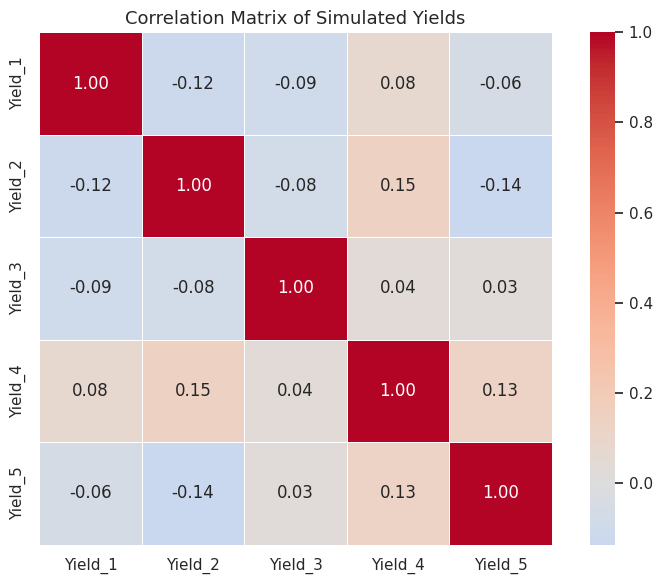

In [ ]:

# Parameters
n_obs = 200
n_vars = 5
mean = 0
std_dev = 0.01
# Generate random variables
yields = np.random.normal(mean, std_dev, size=(n_obs, n_vars))


df_yields = pd.DataFrame(yields, columns=[f'Yield_{i+1}' for i in range(n_vars)])
#save to csv
df_yields.to_csv("simulated_yields.csv", index=False)


print(df_yields.head())


print('Correlation matrix')
corr_matrix = df_yields.corr()
print(corr_matrix)
print(df_yields.corr())


# Plot correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    square=True,
    fmt=".2f",
    linewidths=0.5,)
plt.title("Correlation Matrix of Simulated Yields", fontsize=13)
plt.tight_layout()
plt.show()




Yield Means:
Yield_1    0.000341
Yield_2   -0.000438
Yield_3    0.000484
Yield_4   -0.000250
Yield_5    0.000855
dtype: float64
Yield Standard Deviations:
Yield_1    0.010621
Yield_2    0.010496
Yield_3    0.010517
Yield_4    0.010169
Yield_5    0.009739
dtype: float64
Standardized Yield (first 5 rows):
    Yield_1   Yield_2   Yield_3   Yield_4   Yield_5
0  1.146707 -0.339626 -0.808187  1.954819  0.047652
1  0.478116 -2.056533 -1.535777 -1.863947  0.744161
2  0.957227 -1.937410  0.767285 -1.234329  0.452976
3 -1.481084  0.171311  0.461603  0.262733 -1.337762
4  1.540293 -1.235226 -0.798537  0.545380  0.470873


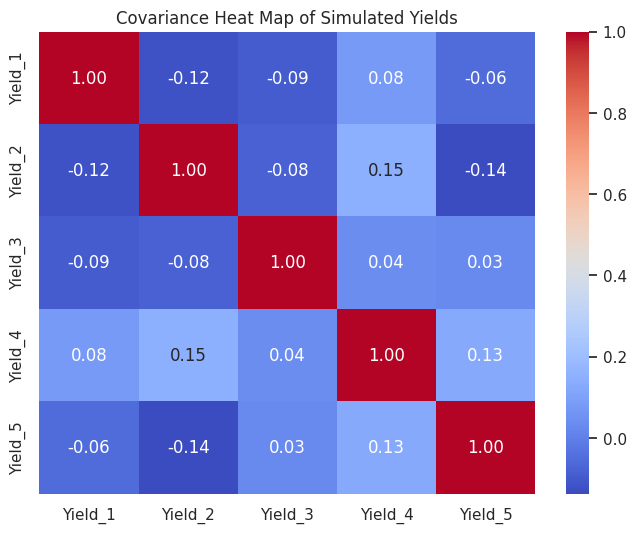

In [ ]:
#Calculate means for all yields in the dataset
yield_means = df_yields.mean()
print("Yield Means:")
print(yield_means)

#Calculate standard deviations for all yields in the dataset
yield_stds = df_yields.std()
print("Yield Standard Deviations:")
print(yield_stds)

standardized_data = (df_yields - yield_means) / yield_stds
print("Standardized Yield (first 5 rows):")
print(standardized_data.head())

# PCA using covariance matrix
covar_matrix_std = standardized_data.cov()

# Heatmap of covariation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(covar_matrix_std, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Covariance Heat Map of Simulated Yields')
plt.show()





In [ ]:
# Eigen decomposition
eigenvalues, eigenvectors = LA.eig(covar_matrix_std)
print("Eigenvalues:")
print(eigenvalues)
print("Eigenvectors (loadings):")
print(eigenvectors)

# Transform standardized data with loadings to get principal components
principal_components = standardized_data.dot(eigenvectors)
principal_components.columns = [f'PC_{i+1}' for i in range(n_vars)]
print("Principal Components (first 5 rows):")
print(principal_components.head())

# Create DataFrame for eigenvalues and explained variance
df_eigval = pd.DataFrame({
    "Eigenvalues": eigenvalues,
    "Explained proportion": eigenvalues / np.sum(eigenvalues)
}, index=[f'PC_{i+1}' for i in range(n_vars)])

print("\nEigenvalues and Explained Proportion:")
print(df_eigval)


Eigenvalues:
[0.63742836 0.94279671 1.10395834 1.14089807 1.17491852]
Eigenvectors (loadings):
[[ 0.42975028  0.36432107  0.77163785 -0.27597293  0.10487528]
 [ 0.56335393 -0.01663495 -0.08485154  0.33250985 -0.75139406]
 [ 0.2531056   0.73220749 -0.42696749  0.30198549  0.35540579]
 [-0.49972042  0.20333852  0.44954221  0.70185644 -0.11934105]
 [ 0.42914345 -0.53806977  0.11395526  0.47903908  0.53277816]]
Principal Components (first 5 rows):
       PC_1      PC_2      PC_3      PC_4      PC_5
0 -0.859502  0.203509  2.142934  0.721380 -0.119682
1 -0.090995 -1.695533  0.446037 -2.231288  1.668503
2  0.325337  0.448059  0.072155 -1.325997  2.217488
3 -1.128538  0.568782 -1.388822  0.148660 -0.864080
4 -0.306507 -0.145452  1.933138 -0.468605  0.991660

Eigenvalues and Explained Proportion:
      Eigenvalues  Explained proportion
PC_1     0.637428              0.127486
PC_2     0.942797              0.188559
PC_3     1.103958              0.220792
PC_4     1.140898              0.228180
P

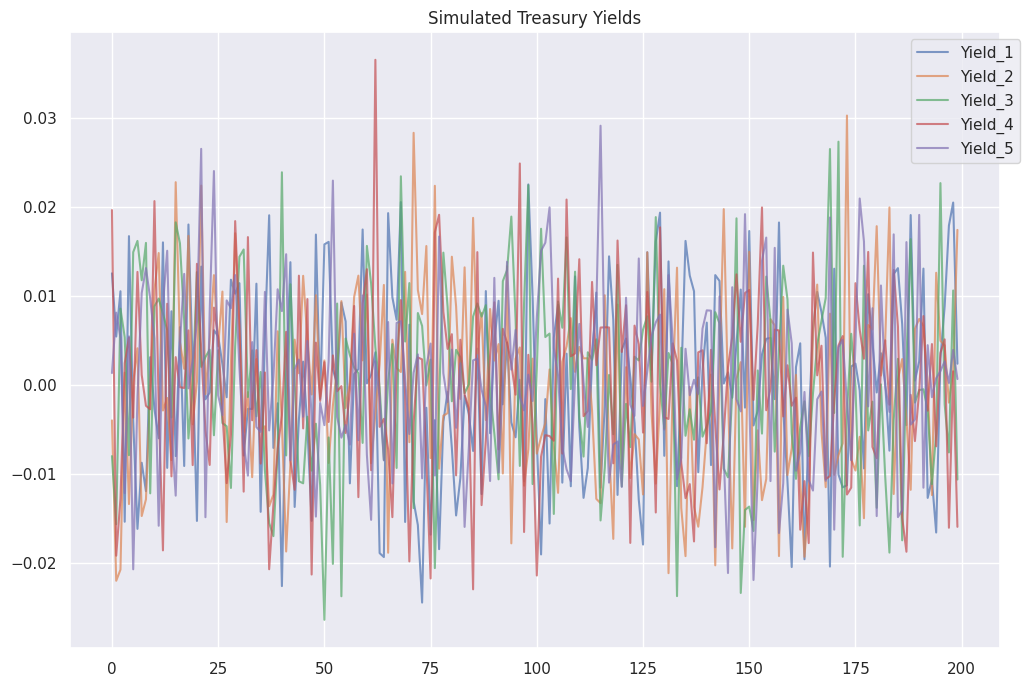

In [ ]:
#Yield Curve (simulated)
df_yields.plot(figsize=(12, 8), title='Simulated Treasury Yields', alpha=0.7)
plt.legend(bbox_to_anchor=(1.03, 1))
plt.show()



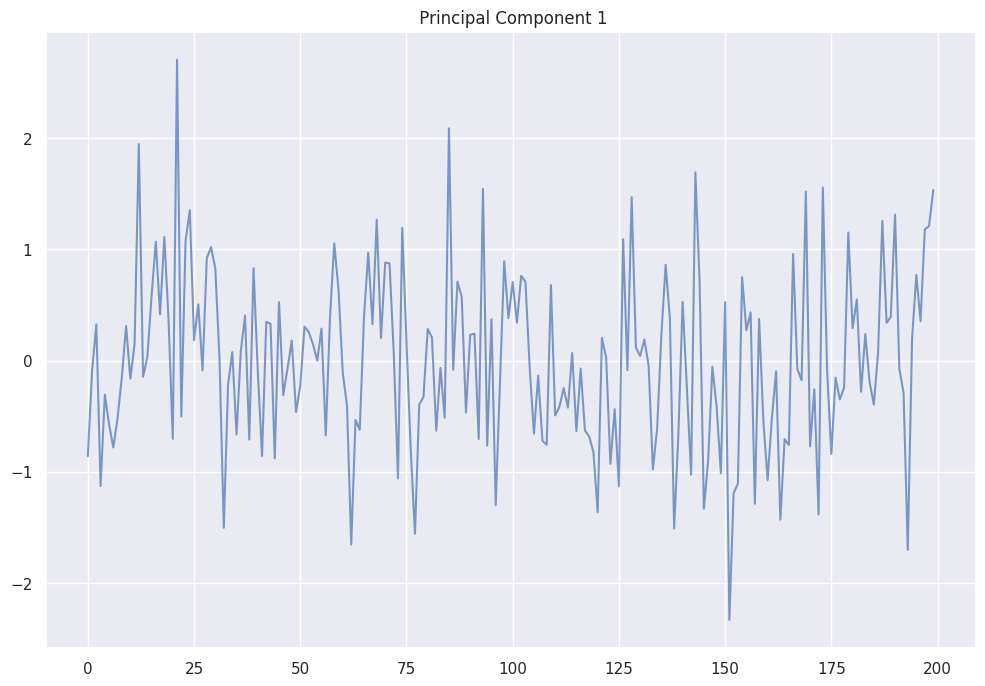

In [ ]:
#  PC_1
principal_components["PC_1"].plot(figsize=(12, 8), title=' Principal Component 1', alpha=0.7)
plt.show()



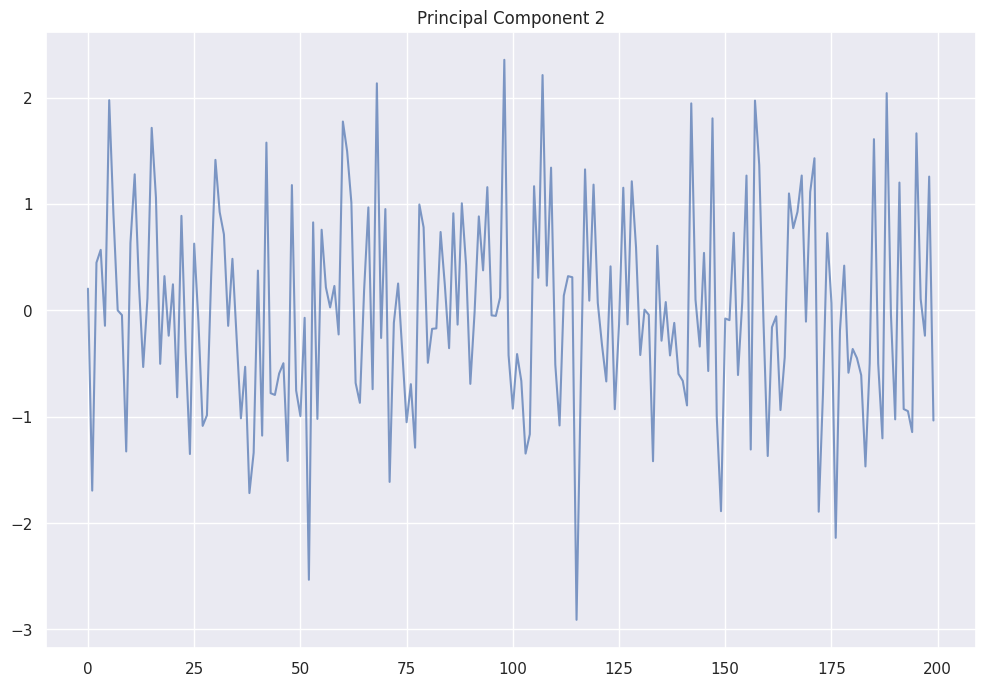

In [ ]:



# PC_2
principal_components["PC_2"].plot(figsize=(12, 8), title='Principal Component 2', alpha=0.7)
plt.show()




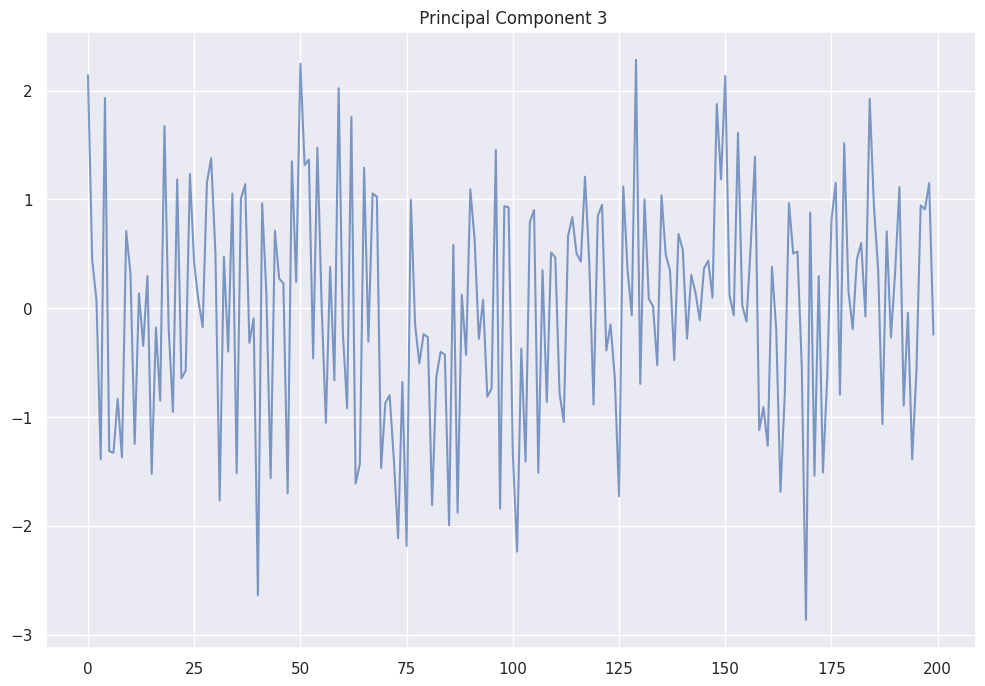

In [ ]:
#PC_3
principal_components["PC_3"].plot(figsize=(12, 8), title=' Principal Component 3', alpha=0.7)
plt.show()

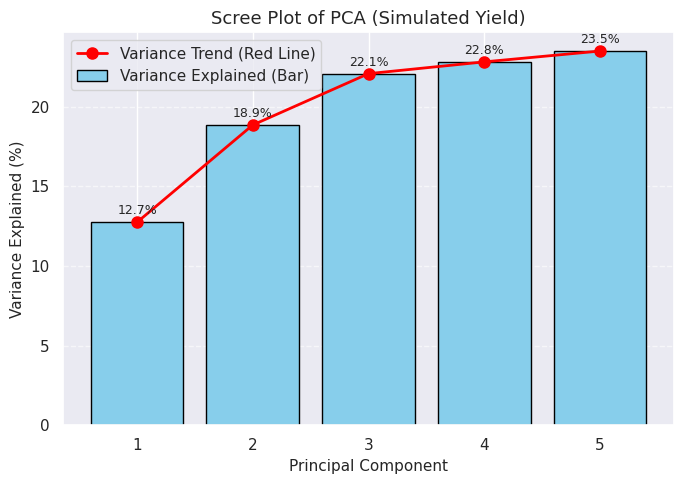

In [ ]:
# # #screeplot

plt.figure(figsize=(7, 5))

# Bar plot for variance explained
plt.bar(
    range(1, n_vars+1),
    df_eigval["Explained proportion"] * 100,
    color='skyblue',
    edgecolor='black',
    label='Variance Explained (Bar)'
)


plt.plot(
    range(1, n_vars+1),
    df_eigval["Explained proportion"] * 100,
    color='red',
    marker='o',
    markersize=8,
    linewidth=2,
    label='Variance Trend (Red Line)'
)

# Annotate percentage values on top of bars
for i, val in enumerate(df_eigval["Explained proportion"] * 100, 1):
    plt.text(i, val + 0.5, f"{val:.1f}%", ha='center', fontsize=9)

plt.title("Scree Plot of PCA (Simulated Yield)", fontsize=13)
plt.xlabel("Principal Component", fontsize=11)
plt.ylabel("Variance Explained (%)", fontsize=11)
plt.xticks(range(1, n_vars+1))
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


## Empirical Treasury Yield Analysis

In [ ]:
!pip install fredapi

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from fredapi import Fred
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [ ]:
sns.set(style="whitegrid")
fred = Fred(api_key="89bdb0d888a85d6cf28a5c2eff2a1896")

# Treasury yield series IDs
series_ids = [
     "DGS1", "DGS2", "DGS3",
    "DGS5", "DGS7"]


In [ ]:
# Time range: last 7 months
end_date = datetime.today()
start_date = end_date - timedelta(days=7 * 30)

Fetched US Treasury Yields:
        Date  DGS1  DGS2  DGS3  DGS5  DGS7
0 2025-03-10  3.98  3.89  3.91  3.98  4.10
1 2025-03-11  4.03  3.94  3.92  4.03  4.16
2 2025-03-12  4.07  4.01  3.98  4.09  4.20
3 2025-03-13  4.03  3.94  3.93  4.02  4.15
4 2025-03-14  4.09  4.02  4.00  4.09  4.20


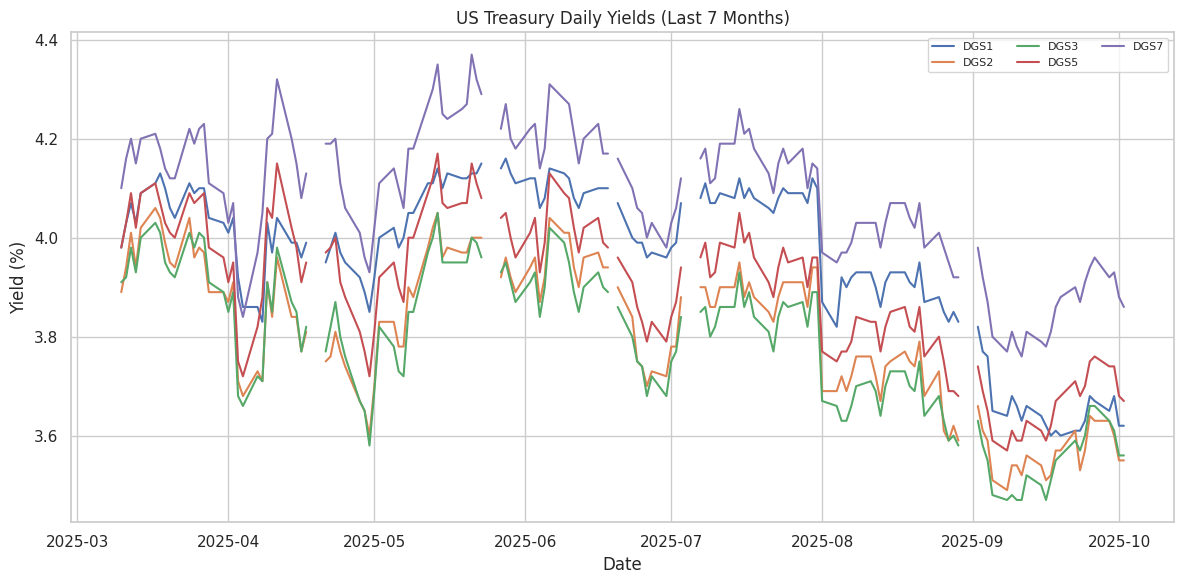

In [ ]:
# Fetch Daily Yields
all_yields = pd.DataFrame()

for sid in series_ids:
    data = fred.get_series(sid, observation_start=start_date, observation_end=end_date)
    all_yields[sid] = data

all_yields.index.name = "Date"
all_yields.reset_index(inplace=True)

print("Fetched US Treasury Yields:")
print(all_yields.head())

#plot
plt.figure(figsize=(12, 6))
for sid in series_ids:
    plt.plot(all_yields["Date"], all_yields[sid], label=sid)

plt.title("US Treasury Daily Yields (Last 7 Months)")
plt.xlabel("Date")
plt.ylabel("Yield (%)")
plt.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

# Save to CSV
all_yields.to_csv("us_treasury_yields_last_7_months.csv", index=False)

In [ ]:
#Compute Daily Yield Changes

daily_changes = all_yields.copy()
daily_changes[series_ids] = daily_changes[series_ids].diff()
daily_changes.dropna(inplace=True)

print(" Daily Yield Changes:")
print(daily_changes.head())

daily_changes.to_csv("us_treasury_daily_yield_changes.csv", index=False)

 Daily Yield Changes:
        Date  DGS1  DGS2  DGS3  DGS5  DGS7
1 2025-03-11  0.05  0.05  0.01  0.05  0.06
2 2025-03-12  0.04  0.07  0.06  0.06  0.04
3 2025-03-13 -0.04 -0.07 -0.05 -0.07 -0.05
4 2025-03-14  0.06  0.08  0.07  0.07  0.05
5 2025-03-17  0.02  0.04  0.03  0.02  0.01


Covariance Matrix of Standardized US government Data:
          DGS1      DGS2      DGS3      DGS5      DGS7
DGS1  1.007299  0.899592  0.865337  0.839711  0.798345
DGS2  0.899592  1.007299  0.958017  0.931768  0.884088
DGS3  0.865337  0.958017  1.007299  0.961967  0.924046
DGS5  0.839711  0.931768  0.961967  1.007299  0.982699
DGS7  0.798345  0.884088  0.924046  0.982699  1.007299


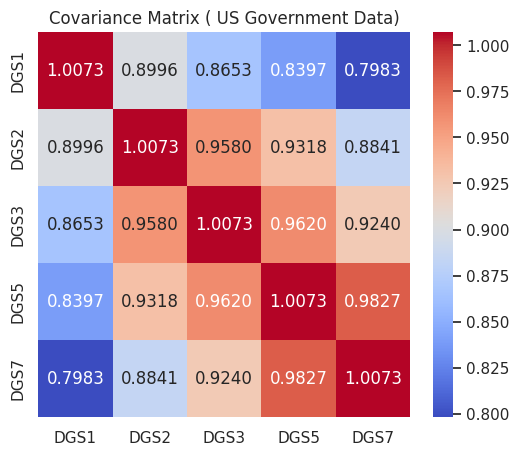

Standardized Daily Yield Changes (first 5 rows):
       DGS1      DGS2      DGS3      DGS5      DGS7
0  1.166298  0.862965  0.205703  0.903871  1.099094
1  0.942135  1.196081  1.050553  1.075919  0.746361
2 -0.851170 -1.135734 -0.808117 -1.160695 -0.840935
3  1.390461  1.362639  1.219523  1.247966  0.922728
4  0.493809  0.696407  0.543643  0.387730  0.217263


In [ ]:
# Standardize Daily Yield Changes

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
daily_changes_scaled = scaler.fit_transform(daily_changes[series_ids])
daily_changes_scaled_df = pd.DataFrame(daily_changes_scaled, columns=series_ids)
# Covariance matrix
cov_matrix = np.cov(daily_changes_scaled_df.T)  # transpose to get variables as rows
cov_df = pd.DataFrame(cov_matrix, index=series_ids, columns=series_ids)
cov_standardized = daily_changes_scaled_df.cov()
print("Covariance Matrix of Standardized US government Data:")
print(cov_df)
plt.figure(figsize=(6,5))
sns.heatmap(cov_standardized, annot=True, fmt=".4f", cmap="coolwarm")
plt.title("Covariance Matrix ( US Government Data)")
plt.show()
print("Standardized Daily Yield Changes (first 5 rows):")
print(daily_changes_scaled_df.head())



In [ ]:
#PCA
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(daily_changes_scaled_df)
# Explained variance
explained_variance = pca.explained_variance_ratio_
print("\nExplained Variance Ratio per Principal Component:")
for i, var in enumerate(explained_variance, 1):
    print(f"PC{i}: {var:.4f} ({var*100:.2f}%)")

# Transform data to principal components
pc_scores = pca.transform(daily_changes_scaled_df)
pc_df = pd.DataFrame(pc_scores, columns=[f'PC_{i+1}' for i in range(len(series_ids))])
print("\nPrincipal Components (first 5 rows):")
print(pc_df.head())





Explained Variance Ratio per Principal Component:
PC1: 0.9190 (91.90%)
PC2: 0.0503 (5.03%)
PC3: 0.0195 (1.95%)
PC4: 0.0081 (0.81%)
PC5: 0.0032 (0.32%)

Principal Components (first 5 rows):
       PC_1      PC_2      PC_3      PC_4      PC_5
0  1.881876  0.183825 -0.589692 -0.499046  0.015178
1  2.244379  0.134876  0.234126 -0.054520  0.152744
2 -2.148581  0.004640 -0.077910  0.225477 -0.220202
3  2.744499  0.349647  0.089771 -0.024397  0.151871
4  1.046791  0.233063  0.263684 -0.040710  0.025239


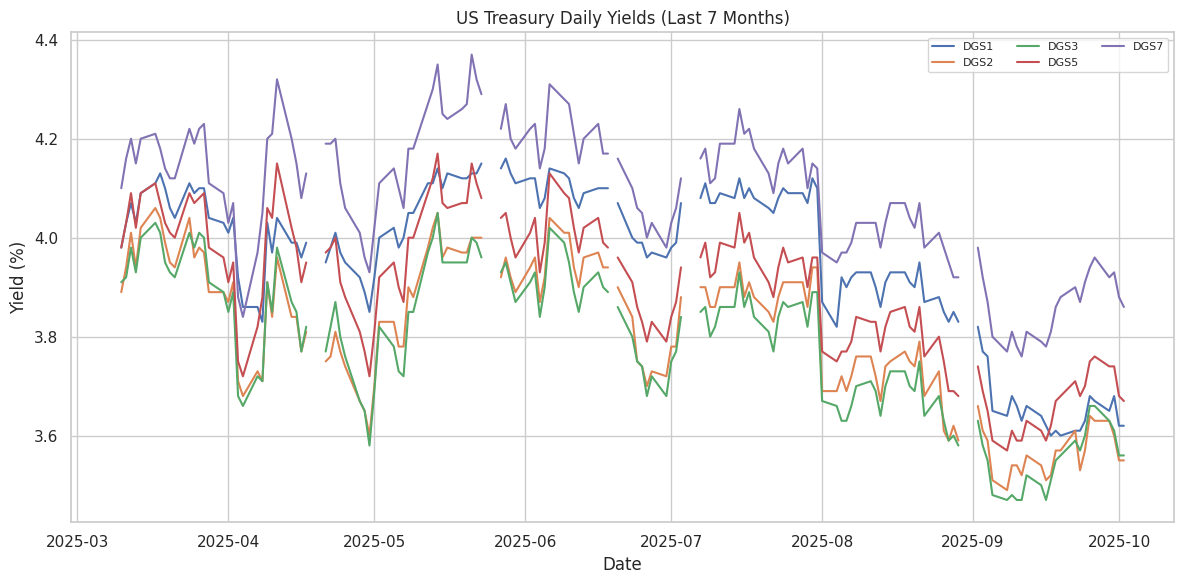

In [ ]:
# Plot Principal Components
# Figure for Daily Yield Curves
plt.figure(figsize=(12, 6))
for sid in series_ids:
    plt.plot(all_yields['Date'], all_yields[sid], label=sid)
plt.title("US Treasury Daily Yields (Last 7 Months)")
plt.xlabel("Date")
plt.ylabel("Yield (%)")
plt.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()



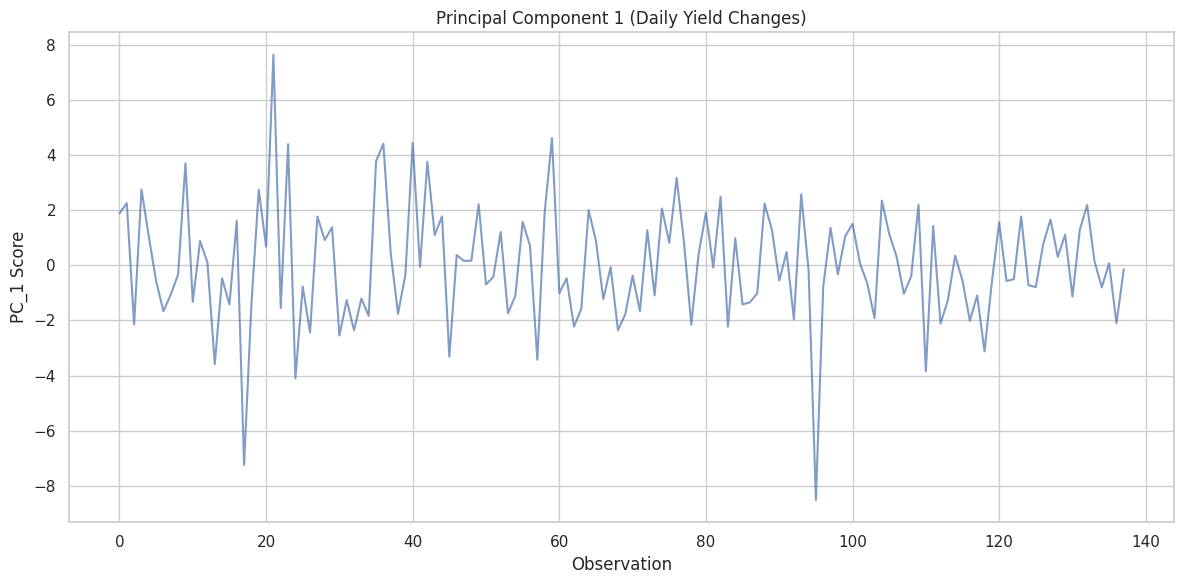

In [ ]:
# Figure for  PC_1
plt.figure(figsize=(12,6))
plt.plot(pc_df['PC_1'], label='PC_1', alpha=0.7)
plt.title("Principal Component 1 (Daily Yield Changes)")
plt.xlabel("Observation")
plt.ylabel("PC_1 Score")
plt.tight_layout()
plt.show()



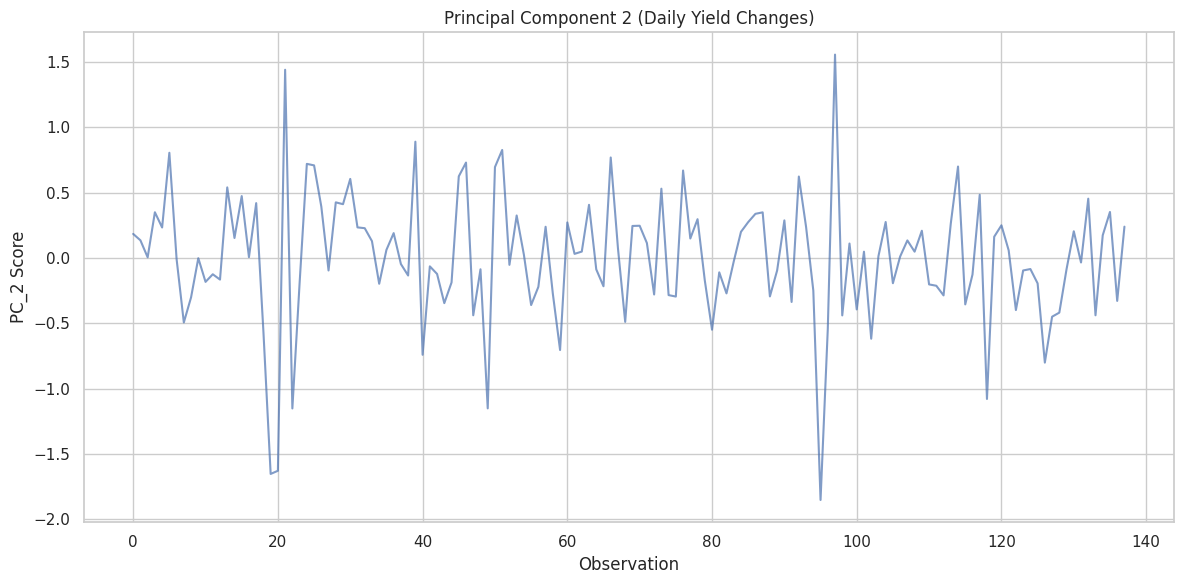

In [ ]:
# Figurefor PC_2
plt.figure(figsize=(12,6))
plt.plot(pc_df['PC_2'], label='PC_2', alpha=0.7)
plt.title("Principal Component 2 (Daily Yield Changes)")
plt.xlabel("Observation")
plt.ylabel("PC_2 Score")
plt.tight_layout()
plt.show()



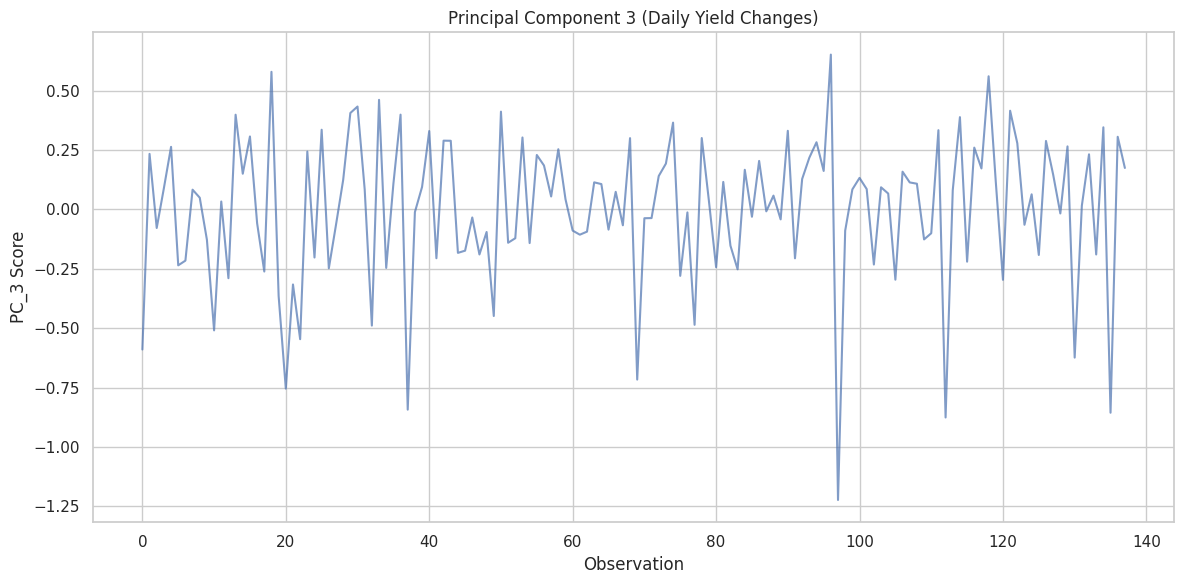

In [ ]:
# Figure for PC_3
plt.figure(figsize=(12,6))
plt.plot(pc_df['PC_3'], label='PC_3', alpha=0.7)
plt.title("Principal Component 3 (Daily Yield Changes)")
plt.xlabel("Observation")
plt.ylabel("PC_3 Score")
plt.tight_layout()
plt.show()

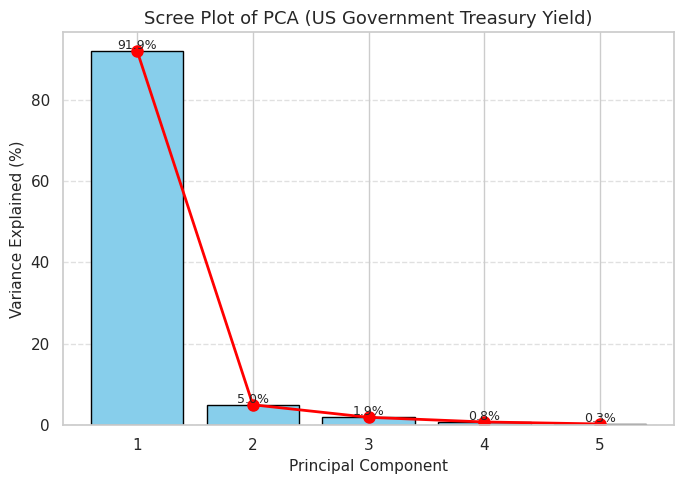

In [ ]:
#Screeplot
plt.figure(figsize=(7, 5))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    color='skyblue',
    edgecolor='black',
    label='Variance Explained (Bar)'
)
plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    color='red',
    marker='o',
    markersize=8,
    linewidth=2,
    label='Variance Trend (Red Line)'
)
for i, val in enumerate(explained_variance * 100, 1):
    plt.text(i, val + 0.5, f"{val:.1f}%", ha='center', fontsize=9)

    plt.title("Scree Plot of PCA (US Government Treasury Yield)", fontsize=13)

plt.xlabel("Principal Component", fontsize=11)
plt.ylabel("Variance Explained (%)", fontsize=11)
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [ ]:
import requests
import pandas as pd
import time
from datetime import datetime, timedelta
import json
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('vgt_complete_30_closing_prices.csv', index_col=0, parse_dates=True)
print(f"Data loaded successfully: {df.shape}")
print(f"   Date range: {df.index.min().date()} to {df.index.max().date()}")
print(f"   Tickers: {list(df.columns)}")

Data loaded successfully: (122, 30)
   Date range: 2025-04-03 to 2025-09-26
   Tickers: ['AAPL', 'ACN', 'ADBE', 'ADI', 'ADSK', 'AMAT', 'AMD', 'AVGO', 'CDNS', 'CRM', 'CRWD', 'CSCO', 'FTNT', 'IBM', 'INTC', 'INTU', 'KLAC', 'LRCX', 'META', 'MSFT', 'MU', 'NOW', 'NVDA', 'ORCL', 'PANW', 'PLTR', 'QCOM', 'SNPS', 'TXN', 'WDAY']


a

In [ ]:
data = {
    'Ticker': ['NVDA', 'MSFT', 'AAPL', 'AVGO', 'ORCL', 'PLTR', 'CSCO', 'AMD', 'CRM', 'IBM',
               'NOW', 'INTU', 'TXN', 'QCOM', 'ACN', 'ADBE', 'ANET', 'APH', 'MU', 'LRCX',
               'AMAT', 'PANW', 'ADI', 'KLAC', 'SNPS', 'APP', 'INTC', 'CRWD', 'CDNS', 'MSI'],
    'Holdings': ['NVIDIA Corp.', 'Microsoft Corp.', 'Apple Inc.', 'Broadcom Inc.', 'Oracle Corp.',
                 'Palantir Technologies Inc. Class A', 'Cisco Systems Inc.', 'Advanced Micro Devices Inc.',
                 'salesforce.com Inc.', 'International Business Machines Corp.', 'ServiceNow Inc.',
                 'Intuit Inc.', 'Texas Instruments Inc.', 'QUALCOMM Inc.', 'Accenture plc Class A',
                 'Adobe Inc.', 'Arista Networks Inc.', 'Amphenol Corp. Class A', 'Micron Technology Inc.',
                 'Lam Research Corp.', 'Applied Materials Inc.', 'Palo Alto Networks Inc.',
                 'Analog Devices Inc.', 'KLA Corp.', 'Synopsys Inc.', 'AppLovin Corp. Class A',
                 'Intel Corp.', 'Crowdstrike Holdings Inc. Class A', 'Cadence Design Systems Inc.',
                 'Motorola Solutions Inc.'],
    'Percent_of_Fund': [17.18, 13.73, 13.05, 4.32, 2.02, 1.86, 1.50, 1.44, 1.32, 1.23,
                        1.04, 1.03, 1.02, 0.99, 0.90, 0.85, 0.84, 0.77, 0.75, 0.74,
                        0.74, 0.73, 0.71, 0.67, 0.67, 0.64, 0.62, 0.61, 0.56, 0.48]
}

holdings_df = pd.DataFrame(data)
print("Top 30 holdings of VGT ETF")
print("Fund Holdings DataFrame:")
print(holdings_df)
print("\nDataFrame Info:")
print(f"Shape: {holdings_df.shape}")
print(f"Columns: {list(holdings_df.columns)}")
print(f"Data types:\n{holdings_df.dtypes}")
print("\nSummary Statistics for Percent of Fund:")
print(holdings_df['Percent_of_Fund'].describe())
print("\nTop 10 Holdings:")
print(holdings_df.head(10)[['Ticker', 'Holdings', 'Percent_of_Fund']])

Top 30 holdings of VGT ETF
Fund Holdings DataFrame:
   Ticker                               Holdings  Percent_of_Fund
0    NVDA                           NVIDIA Corp.            17.18
1    MSFT                        Microsoft Corp.            13.73
2    AAPL                             Apple Inc.            13.05
3    AVGO                          Broadcom Inc.             4.32
4    ORCL                           Oracle Corp.             2.02
5    PLTR     Palantir Technologies Inc. Class A             1.86
6    CSCO                     Cisco Systems Inc.             1.50
7     AMD            Advanced Micro Devices Inc.             1.44
8     CRM                    salesforce.com Inc.             1.32
9     IBM  International Business Machines Corp.             1.23
10    NOW                        ServiceNow Inc.             1.04
11   INTU                            Intuit Inc.             1.03
12    TXN                 Texas Instruments Inc.             1.02
13   QCOM               

 b

the data was obtained from AlphaVantage's api

 c

TASK C: COMPUTING DAILY RETURNS WITH VISUALIZATIONS
 Data loaded successfully: (122, 30)
   Date range: 2025-04-03 to 2025-09-26

Daily returns calculated:
   Shape: (121, 30)
   Date range: 2025-04-04 to 2025-09-26
   Number of tickers: 30

 Daily returns saved to 'vgt_daily_returns.csv'

 Creating Visualization 1: Daily Price Time Series


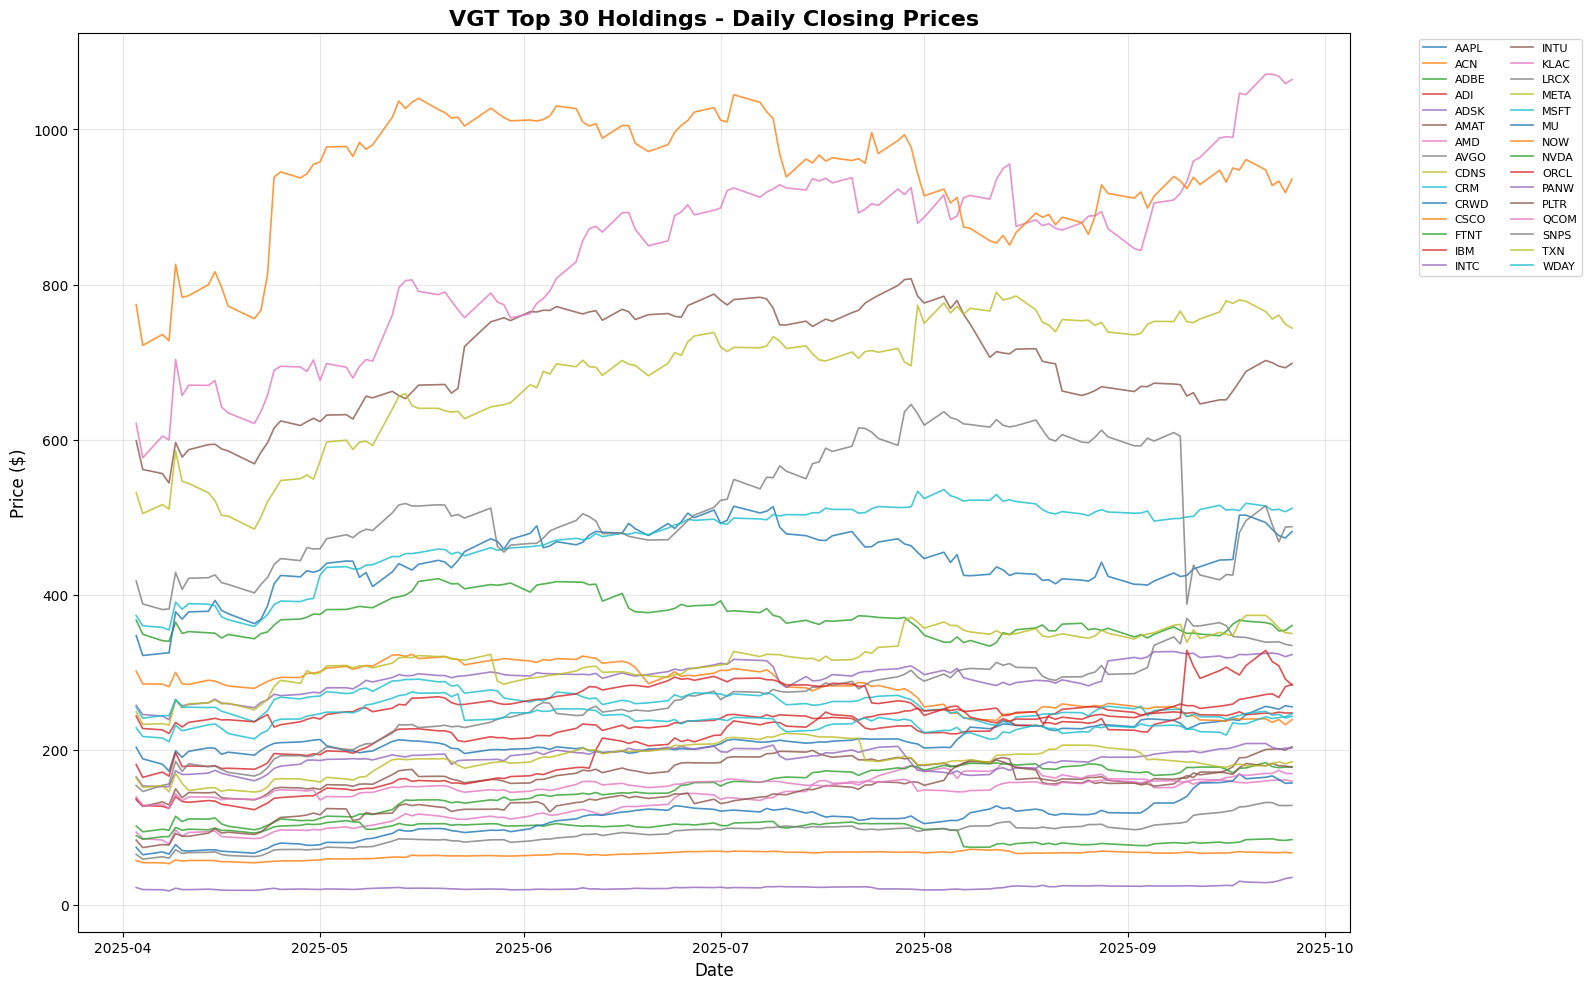

 Daily price time series plot displayed

 Creating Visualization 2: Cumulative Returns


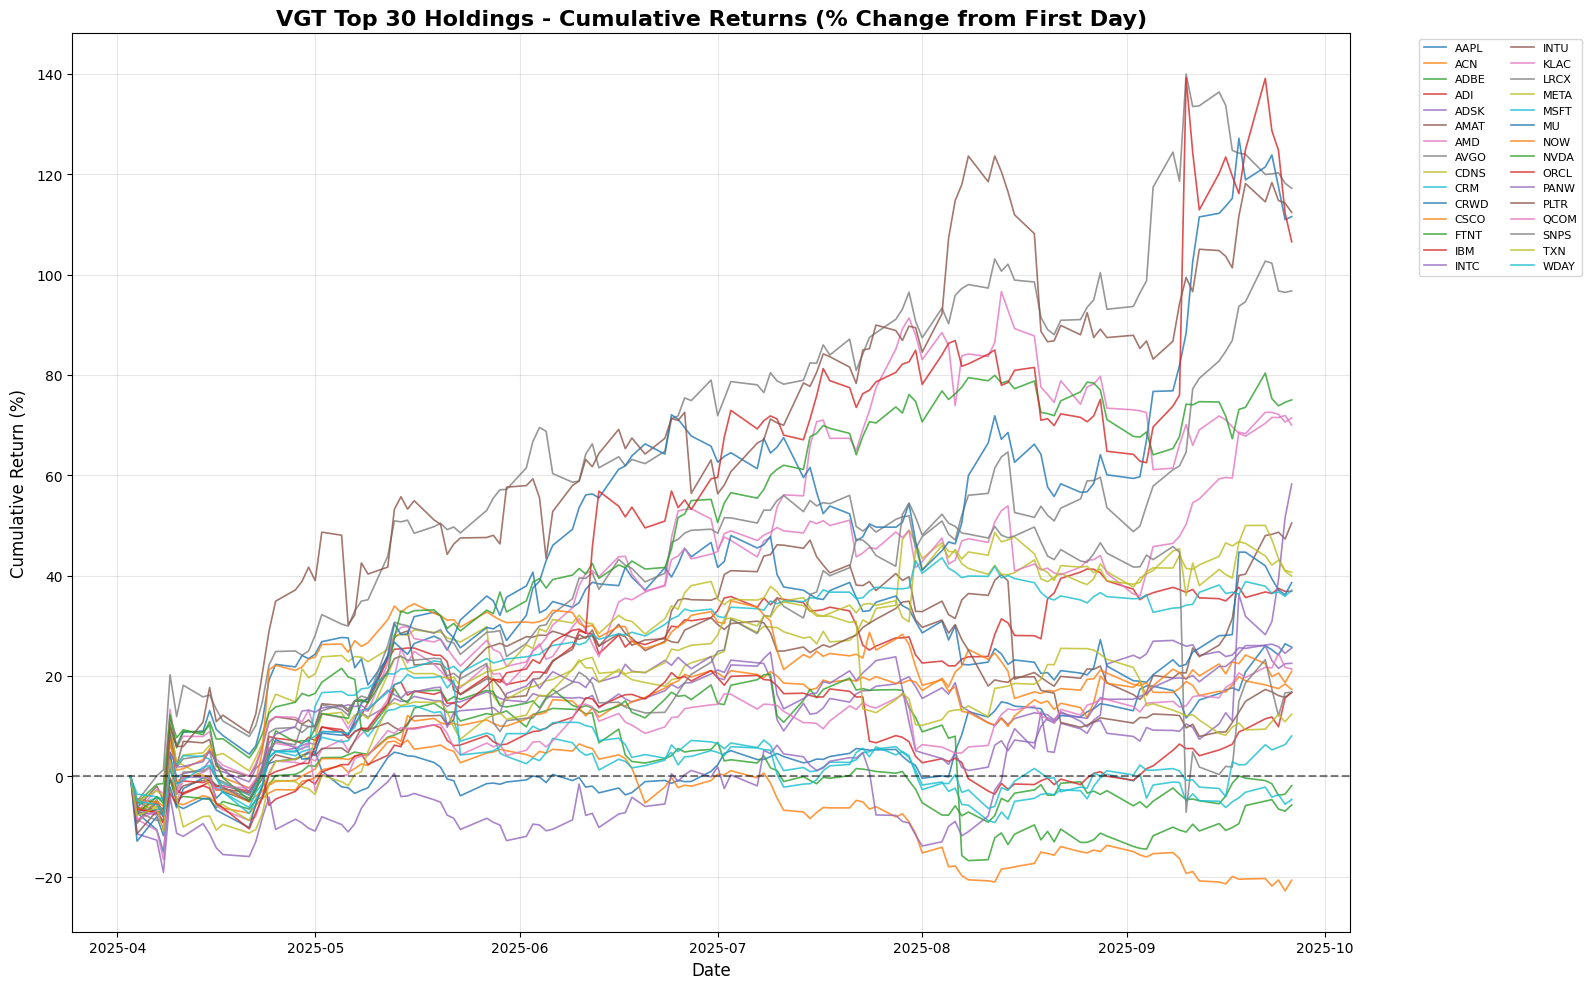

 Cumulative returns plot displayed

 Data saved:
   - Daily returns: 'vgt_daily_returns.csv'
   - Cumulative returns: 'vgt_cumulative_returns.csv'

TASK C COMPLETE WITH REQUESTED VISUALIZATIONS


In [ ]:
print("=" * 60)
print("COMPUTING DAILY RETURNS WITH VISUALIZATIONS")
print("=" * 60)

try:
    df_prices = pd.read_csv('vgt_complete_30_closing_prices.csv', index_col=0, parse_dates=True)
    print(f" Data loaded successfully: {df_prices.shape}")
    print(f"   Date range: {df_prices.index.min().date()} to {df_prices.index.max().date()}")
except FileNotFoundError:
    print("❌ File not found. Make sure 'vgt_complete_30_closing_prices.csv' is in the directory")

daily_returns = df_prices.pct_change().dropna()

print(f"\nDaily returns calculated:")
print(f"   Shape: {daily_returns.shape}")
print(f"   Date range: {daily_returns.index.min().date()} to {daily_returns.index.max().date()}")
print(f"   Number of tickers: {len(daily_returns.columns)}")

daily_returns.to_csv('vgt_daily_returns.csv')
print("\n Daily returns saved to 'vgt_daily_returns.csv'")

print("\n Creating Visualization 1: Daily Price Time Series")

plt.figure(figsize=(16, 10))
for ticker in df_prices.columns:
    plt.plot(df_prices.index, df_prices[ticker], label=ticker, linewidth=1.2, alpha=0.8)

plt.title('VGT Top 30 Holdings - Daily Closing Prices', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Price ($)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2, fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(" Daily price time series plot displayed")

print("\n Creating Visualization 2: Cumulative Returns")

cumulative_returns = (df_prices / df_prices.iloc[0] - 1) * 100

plt.figure(figsize=(16, 10))
for ticker in cumulative_returns.columns:
    plt.plot(cumulative_returns.index, cumulative_returns[ticker], label=ticker, linewidth=1.2, alpha=0.8)

plt.title('VGT Top 30 Holdings - Cumulative Returns (% Change from First Day)', fontsize=16, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Cumulative Return (%)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2, fontsize=8)
plt.grid(True, alpha=0.3)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print(" Cumulative returns plot displayed")

cumulative_returns.to_csv('vgt_cumulative_returns.csv')

print("\n Data saved:")
print("   - Daily returns: 'vgt_daily_returns.csv'")
print("   - Cumulative returns: 'vgt_cumulative_returns.csv'")

print("\n" + "=" * 60)
print("TASK C COMPLETE WITH REQUESTED VISUALIZATIONS")
print("=" * 60)


 d

TASK D: COMPUTING COVARIANCE MATRIX
 Daily returns loaded from file

Covariance matrix computed:
   Shape: (30, 30)
   Diagonal (variance) range: 0.000248 to 0.002013


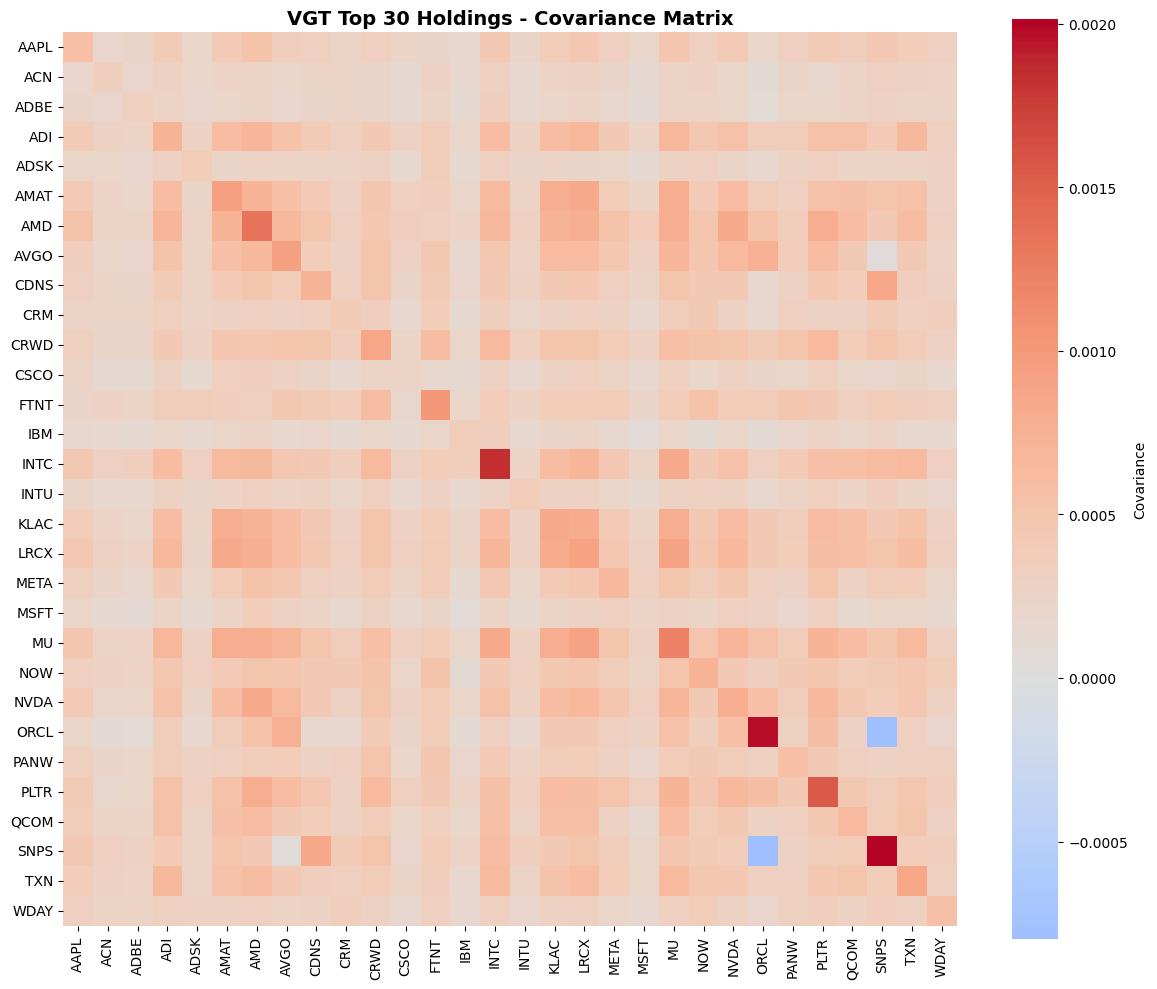


 COVARIANCE MATRIX SUMMARY:
----------------------------------------
Average covariance (off-diagonal): 0.000360
Max covariance: 0.000897
Min covariance: -0.000797

 Covariance matrix saved to 'vgt_covariance_matrix.csv'


In [ ]:
print("=" * 60)
print("COMPUTING COVARIANCE MATRIX")
print("=" * 60)

try:
    daily_returns = pd.read_csv('vgt_daily_returns.csv', index_col=0, parse_dates=True)
    print(" Daily returns loaded from file")
except FileNotFoundError:
    print(" Daily returns file not found. Please run Task C first.")

covariance_matrix = daily_returns.cov()

print(f"\nCovariance matrix computed:")
print(f"   Shape: {covariance_matrix.shape}")
print(f"   Diagonal (variance) range: {np.diag(covariance_matrix).min():.6f} to {np.diag(covariance_matrix).max():.6f}")

plt.figure(figsize=(12, 10))
sns.heatmap(covariance_matrix,
            annot=False,
            cmap='coolwarm',
            center=0,
            square=True,
            cbar_kws={'label': 'Covariance'})
plt.title('VGT Top 30 Holdings - Covariance Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n COVARIANCE MATRIX SUMMARY:")
print("-" * 40)
off_diagonal = covariance_matrix.values[np.triu_indices_from(covariance_matrix.values, k=1)]
print(f"Average covariance (off-diagonal): {off_diagonal.mean():.6f}")
print(f"Max covariance: {off_diagonal.max():.6f}")
print(f"Min covariance: {off_diagonal.min():.6f}")

covariance_matrix.to_csv('vgt_covariance_matrix.csv')
print("\n Covariance matrix saved to 'vgt_covariance_matrix.csv'")

 e

TASK E: COMPUTING PRINCIPAL COMPONENT ANALYSIS (PCA)
 Daily returns loaded from file

PCA Analysis Results:
   Number of components: 30
   First 5 components explain: 72.47% of variance
   First 10 components explain: 84.15% of variance


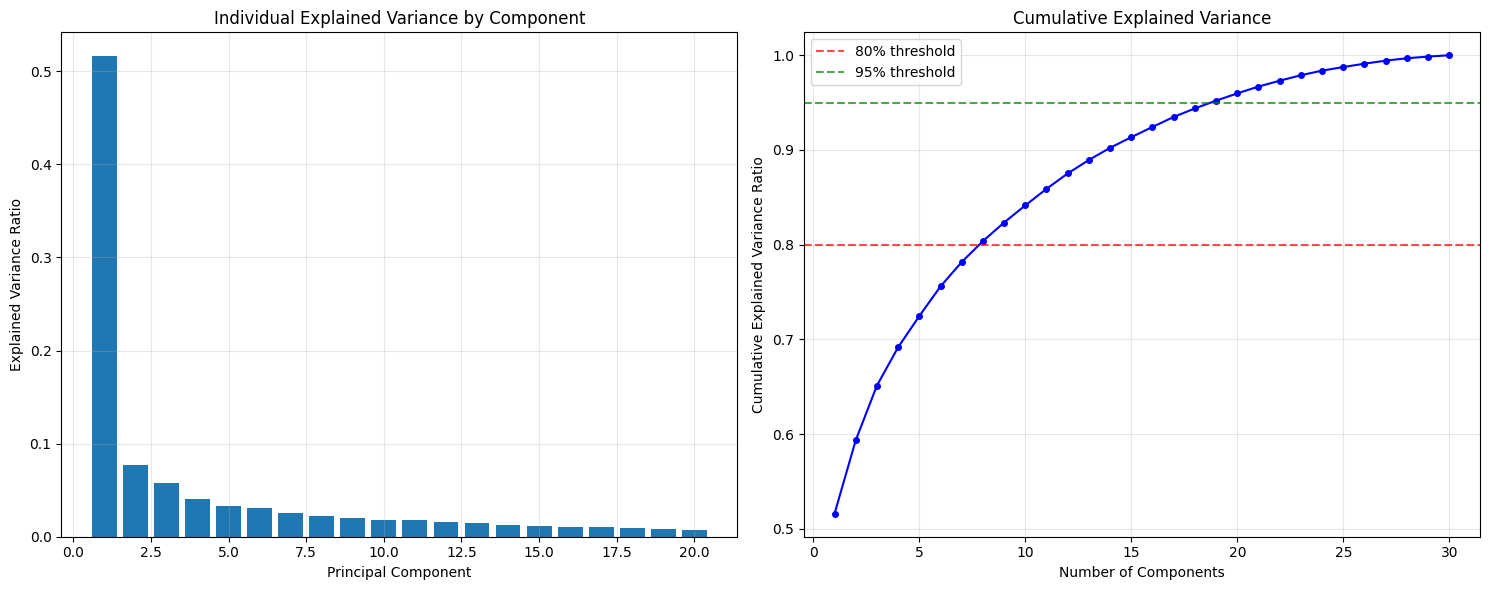


 PCA LOADINGS (First 5 Components):
--------------------------------------------------
         PC1     PC2     PC3     PC4     PC5
AAPL  0.1892 -0.0070 -0.1196  0.0065 -0.1047
ACN   0.1708 -0.2475 -0.0358 -0.2341 -0.1042
ADBE  0.1668 -0.2471 -0.0296 -0.2318 -0.0745
ADI   0.2214  0.1018 -0.1271 -0.1649 -0.1013
ADSK  0.1721 -0.2587  0.1711 -0.1277  0.0602
AMAT  0.2020  0.1948 -0.2111 -0.0615  0.0451
AMD   0.1896  0.2131 -0.0835  0.0859 -0.0973
AVGO  0.1882  0.2237  0.2256 -0.0109  0.0040
CDNS  0.1843 -0.1449 -0.1199  0.3434 -0.0255
CRM   0.1947 -0.2727  0.0813 -0.1060 -0.2065
CRWD  0.1922 -0.0685  0.1506  0.2242  0.2519
CSCO  0.1971  0.0708  0.0140  0.0607  0.0678
FTNT  0.1552 -0.2054  0.2904  0.0650  0.1436
IBM   0.1365 -0.1172 -0.0952 -0.0512  0.6087
INTC  0.1525  0.0103 -0.1802 -0.1347  0.2446
INTU  0.1737 -0.1501  0.0577  0.1290  0.1897
KLAC  0.2158  0.2034 -0.1423 -0.0527  0.0904
LRCX  0.2179  0.2002 -0.1781 -0.0594 -0.0066
META  0.1839  0.0734  0.0897  0.2482 -0.2130
MSFT  0.1842

In [ ]:
print("=" * 60)
print("COMPUTING PRINCIPAL COMPONENT ANALYSIS (PCA)")
print("=" * 60)

try:
    daily_returns = pd.read_csv('vgt_daily_returns.csv', index_col=0, parse_dates=True)
    print(" Daily returns loaded from file")
except FileNotFoundError:
    print(" Daily returns file not found. Please run Task C first.")

scaler = StandardScaler()
returns_scaled = scaler.fit_transform(daily_returns)

pca = PCA()
pca_components = pca.fit_transform(returns_scaled)

n_components = len(daily_returns.columns)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print(f"\nPCA Analysis Results:")
print(f"   Number of components: {n_components}")
if len(cumulative_variance) > 4:
    print(f"   First 5 components explain: {cumulative_variance[4]:.2%} of variance")
if len(cumulative_variance) > 9:
    print(f"   First 10 components explain: {cumulative_variance[9]:.2%} of variance")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.bar(range(1, min(21, n_components + 1)), explained_variance[:20])
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Individual Explained Variance by Component')
ax1.grid(True, alpha=0.3)

ax2.plot(range(1, n_components + 1), cumulative_variance, 'bo-', markersize=4)
ax2.axhline(y=0.8, color='r', linestyle='--', alpha=0.7, label='80% threshold')
ax2.axhline(y=0.95, color='g', linestyle='--', alpha=0.7, label='95% threshold')
ax2.set_xlabel('Number of Components')
ax2.set_ylabel('Cumulative Explained Variance Ratio')
ax2.set_title('Cumulative Explained Variance')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

n_display = min(5, n_components)
loadings_df = pd.DataFrame(
    pca.components_[:n_display].T,
    columns=[f'PC{i+1}' for i in range(n_display)],
    index=daily_returns.columns
)

print(f"\n PCA LOADINGS (First {n_display} Components):")
print("-" * 50)
print(loadings_df.round(4))

loadings_df.to_csv('vgt_pca_loadings.csv')

variance_df = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(n_components)],
    'Explained_Variance_Ratio': explained_variance,
    'Cumulative_Variance_Ratio': cumulative_variance
})
variance_df.to_csv('vgt_pca_explained_variance.csv', index=False)

print("\n PCA results saved:")
print("   - Loadings: 'vgt_pca_loadings.csv'")
print("   - Explained variance: 'vgt_pca_explained_variance.csv'")


 f

TASK F: COMPUTING SINGULAR VALUE DECOMPOSITION (SVD)
 Daily returns loaded from file

SVD Analysis Results:
   Matrix dimensions: (121, 30)
   Number of singular values: 30
   First 5 components explain: 72.47% of variance
   First 10 components explain: 84.15% of variance


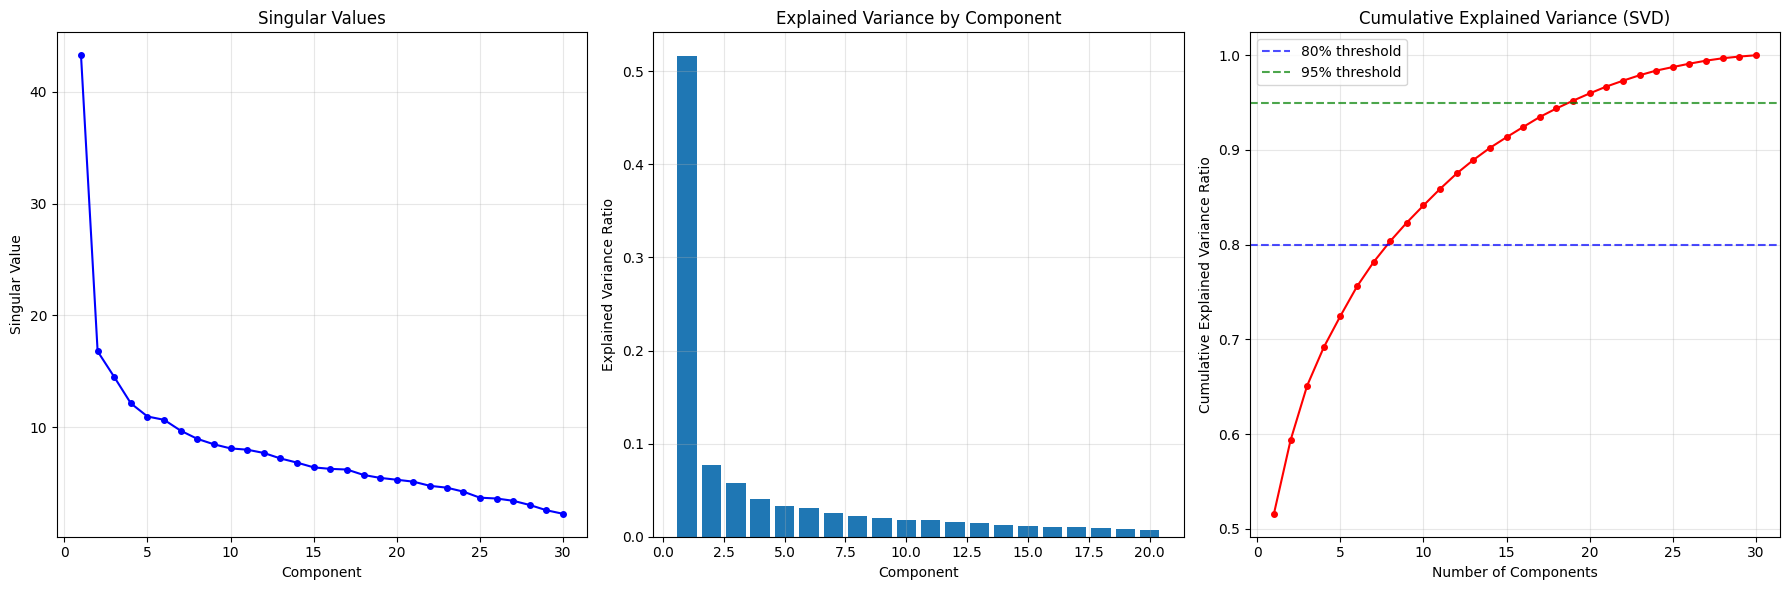


 SVD RIGHT SINGULAR VECTORS (First 5 Components):
-------------------------------------------------------
      Component_1  Component_2  Component_3  Component_4  Component_5
AAPL       0.1892      -0.0070       0.1196      -0.0065       0.1047
ACN        0.1708      -0.2475       0.0358       0.2341       0.1042
ADBE       0.1668      -0.2471       0.0296       0.2318       0.0745
ADI        0.2214       0.1018       0.1271       0.1649       0.1013
ADSK       0.1721      -0.2587      -0.1711       0.1277      -0.0602
AMAT       0.2020       0.1948       0.2111       0.0615      -0.0451
AMD        0.1896       0.2131       0.0835      -0.0859       0.0973
AVGO       0.1882       0.2237      -0.2256       0.0109      -0.0040
CDNS       0.1843      -0.1449       0.1199      -0.3434       0.0255
CRM        0.1947      -0.2727      -0.0813       0.1060       0.2065
CRWD       0.1922      -0.0685      -0.1506      -0.2242      -0.2519
CSCO       0.1971       0.0708      -0.0140      -0.0

In [ ]:
print("=" * 60)
print("COMPUTING SINGULAR VALUE DECOMPOSITION (SVD)")
print("=" * 60)

try:
    daily_returns = pd.read_csv('vgt_daily_returns.csv', index_col=0, parse_dates=True)
    print(" Daily returns loaded from file")
except FileNotFoundError:
    print(" Daily returns file not found. Please run Task C first.")

scaler = StandardScaler()
returns_scaled = scaler.fit_transform(daily_returns)

U, sigma, Vt = np.linalg.svd(returns_scaled, full_matrices=False)

explained_variance = (sigma ** 2) / (len(daily_returns) - 1)
total_variance = explained_variance.sum()
explained_variance_ratio = explained_variance / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)

print(f"\nSVD Analysis Results:")
print(f"   Matrix dimensions: {returns_scaled.shape}")
print(f"   Number of singular values: {len(sigma)}")

if len(cumulative_variance) > 4:
    print(f"   First 5 components explain: {cumulative_variance[4]:.2%} of variance")
if len(cumulative_variance) > 9:
    print(f"   First 10 components explain: {cumulative_variance[9]:.2%} of variance")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

ax1.plot(range(1, len(sigma) + 1), sigma, 'bo-', markersize=4)
ax1.set_xlabel('Component')
ax1.set_ylabel('Singular Value')
ax1.set_title('Singular Values')
ax1.grid(True, alpha=0.3)

components_to_show = min(20, len(explained_variance_ratio))
ax2.bar(range(1, components_to_show + 1), explained_variance_ratio[:components_to_show])
ax2.set_xlabel('Component')
ax2.set_ylabel('Explained Variance Ratio')
ax2.set_title('Explained Variance by Component')
ax2.grid(True, alpha=0.3)

ax3.plot(range(1, len(sigma) + 1), cumulative_variance, 'ro-', markersize=4)
ax3.axhline(y=0.8, color='b', linestyle='--', alpha=0.7, label='80% threshold')
ax3.axhline(y=0.95, color='g', linestyle='--', alpha=0.7, label='95% threshold')
ax3.set_xlabel('Number of Components')
ax3.set_ylabel('Cumulative Explained Variance Ratio')
ax3.set_title('Cumulative Explained Variance (SVD)')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

n_display = min(5, len(sigma))
svd_components_df = pd.DataFrame(
    Vt[:n_display].T,
    columns=[f'Component_{i+1}' for i in range(n_display)],
    index=daily_returns.columns
)

print(f"\n SVD RIGHT SINGULAR VECTORS (First {n_display} Components):")
print("-" * 55)
print(svd_components_df.round(4))

print("\n SVD EIGENVALUE ANALYSIS:")
print("-" * 35)
eigenvalues = sigma ** 2 / (len(daily_returns) - 1)
for i in range(min(10, len(eigenvalues))):
    print(f"   Eigenvalue {i+1:2d}: {eigenvalues[i]:.6f} ({explained_variance_ratio[i]:.2%})")

print(f"\n SVD SUMMARY STATISTICS:")
print("-" * 35)
print(f"   Total variance explained: {cumulative_variance[-1]:.4f}")
print(f"   Largest singular value: {sigma[0]:.4f}")
print(f"   Smallest singular value: {sigma[-1]:.4f}")
print(f"   Condition number: {sigma[0]/sigma[-1]:.2f}")

components_80 = np.argmax(cumulative_variance >= 0.8) + 1
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

print(f"\n DIMENSIONALITY REDUCTION SUMMARY:")
print("-" * 40)
print(f"   Components for 80% variance: {components_80}")
print(f"   Components for 95% variance: {components_95}")
print(f"   Original dimensions: {len(sigma)}")
print(f"   Reduction ratio (80%): {components_80/len(sigma):.2%}")
print(f"   Reduction ratio (95%): {components_95/len(sigma):.2%}")

svd_components_df.to_csv('vgt_svd_components.csv')

svd_summary_df = pd.DataFrame({
    'Component': [f'Component_{i+1}' for i in range(len(sigma))],
    'Singular_Value': sigma,
    'Eigenvalue': eigenvalues,
    'Explained_Variance_Ratio': explained_variance_ratio,
    'Cumulative_Variance_Ratio': cumulative_variance
})
svd_summary_df.to_csv('vgt_svd_summary.csv', index=False)

print("\n SVD results saved:")
print("   - Components: 'vgt_svd_components.csv'")
print("   - Summary: 'vgt_svd_summary.csv'")
